# Homework Module 2: Machine Learning for Regression

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [45]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"

In [46]:
!wget -O data/homework_data.csv $data

--2026-10-05 22:27:58--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘data/homework_data.csv’

data/homework_data. 100%[===================>] 620.29K  --.-KB/s    in 0.03s   

2026-10-05 22:27:58 (19.2 MB/s) - ‘data/homework_data.csv’ saved [635180/635180]



In [47]:
df = pd.read_csv('data/homework_data.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [48]:
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## EDA

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

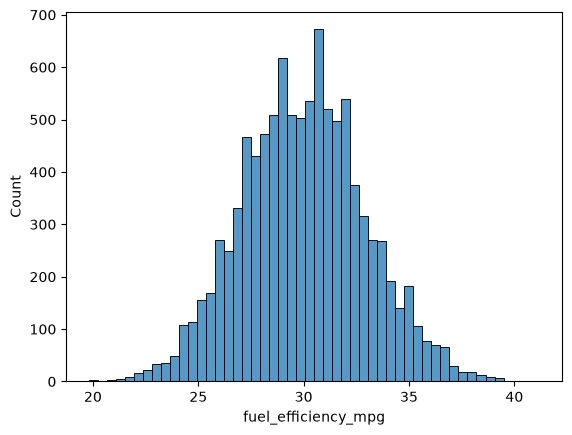

In [49]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

Q. Look at the fuel_efficiency_mpg variable. Does it have a long tail?
A. No, it doesn't

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

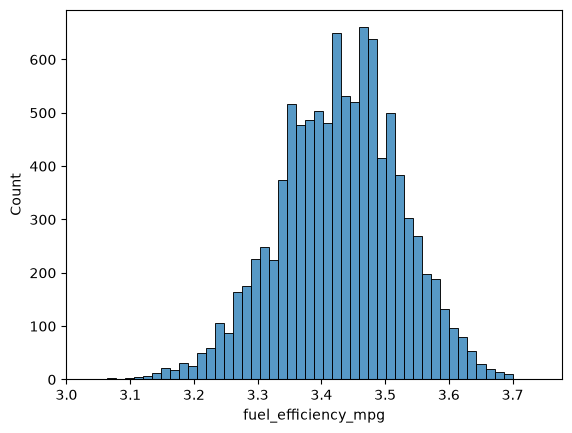

In [50]:
# What happens if we apply the log transformation to the target? It doesn't look like a normal distribution as it would if we didn't apply the log transformation.
fuel_efficiency_logs = np.log1p(df.fuel_efficiency_mpg)
sns.histplot(fuel_efficiency_logs, bins=50)

## Question 1.
There's one column with missing values. What is it?

- 'engine_displacement'
- 'horsepower'
- 'vehicle_weight'
- 'model_year'

In [51]:
df.isnull().sum()[lambda x: x > 0]

horsepower    877
dtype: int64

### Answer for Question 1

The column with missing values is **horsepower**.


## Question 2.
What's the median (50% percentile) for variable 'horsepower'?
- 204
- 254
- 304
- 354

In [52]:
df.describe()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


### Answer for Question 2

The median horsepower is **254.0**.


### Prepare and split the dataset
- Shuffle the dataset (the filtered one you created above), use seed 42.
- Split your data in train/val/test sets, with 60%/20%/20% distribution.


In [53]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test
n, n_train + n_val + n_test
print(n, n_train, n_val, n_test)

10000 6000 2000 2000


In [54]:
idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)
idx

array([6252, 4684, 1731, ..., 5390,  860, 7270], shape=(10000,))

In [55]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [56]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [57]:
# Target values
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [58]:
# Removing target from dataframes
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

## Question 3
- We need to deal with missing values for the column from Q1.
- We have two options: fill it with 0 or with the mean of this variable.
- Try both options. For each, train a linear regression model without regularization using the code from the lessons.
- For computing the mean, use the training only!
- Use the validation dataset to evaluate the models and compare the RMSE of each option.
- Round the RMSE scores to 3 decimal digits using `round(score, 3)`. This keeps the imputation difference visible in this release.
- Which option gives better RMSE?

Options:

- With 0
- With mean
- Both are equally good


In [59]:
def train_linear_regression(X, y):
    ones = np.ones((X.shape[0]))
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    w0 = w_full[0]
    w = w_full[1:]
    return w0, w # Return intercept and weights

In [60]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [61]:
X_train = df_train.fillna(0).values
X_train

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

In [62]:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(-153.8849618823138),
 array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01]))

In [63]:
# Prepare validation set
X_val = df_val.fillna(0).values
def prepare_X(df):
    df_num = df
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [64]:
# Make predictions
y_pred = w0 + X_train.dot(w)
y_pred

array([34.07471478, 29.24093577, 32.95179055, ..., 29.32203017,
       31.8448482 , 29.69112172], shape=(6000,))

<Axes: ylabel='Count'>

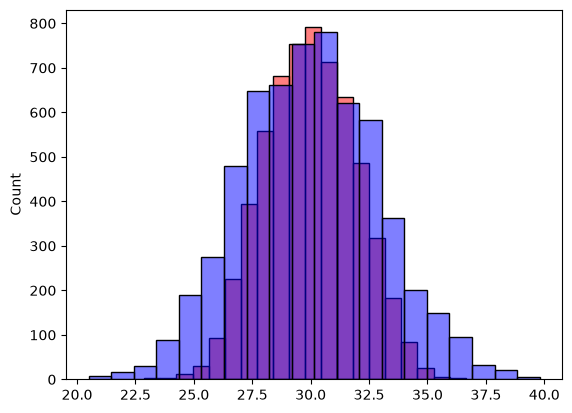

In [65]:
# Compare distributions of y_pred and y_train
sns.histplot(y_pred, color='red', alpha=0.5, bins=20)
sns.histplot(y_train, color='blue', alpha=0.5, bins=20)

In [66]:
# Train the model again on the training set and evaluate on the validation set
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse_fill_0 = rmse(y_val, y_pred)
rmse_fill_0

np.float64(2.20529319475341)

### Filling missing values with mean

In [67]:
X_train = df_train.fillna(df_train.mean()).values

In [68]:
# Prepare validation set
X_val = df_val.fillna(df_val.mean()).values
def prepare_X(df):
    df_num = df
    df_num = df_num.fillna(df.mean())
    X = df_num.values
    return X

In [69]:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(-153.29645639114293),
 array([-0.00102386, -0.00648622, -0.00388828,  0.10197897]))

In [70]:
# Make predictions
y_pred = w0 + X_train.dot(w)
y_pred

array([33.9590606 , 29.31436861, 32.76131994, ..., 29.30040609,
       31.92376266, 29.67268373], shape=(6000,))

<Axes: ylabel='Count'>

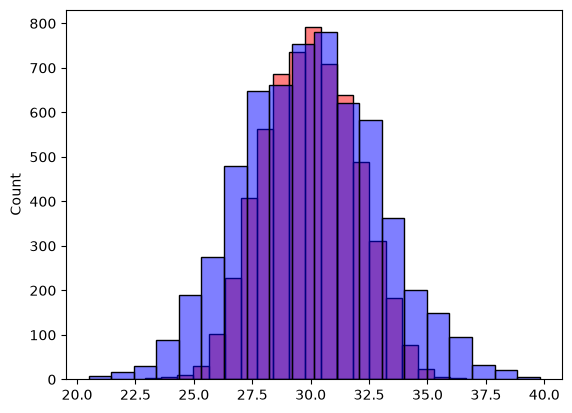

In [71]:
# Compare distributions of y_pred and y_train
sns.histplot(y_pred, color='red', alpha=0.5, bins=20)
sns.histplot(y_train, color='blue', alpha=0.5, bins=20)

In [72]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse_fill_mean = rmse(y_val, y_pred)
rmse_fill_mean

np.float64(2.2018099164429406)

In [73]:
print("RMSE with filling missing values with 0:", round(rmse_fill_0, 3))
print("RMSE with filling missing values with mean:", round(rmse_fill_mean, 3))


RMSE with filling missing values with 0: 2.205
RMSE with filling missing values with mean: 2.202


### Answer for Question 3

The better option is to fill missing values with the mean.

RMSE with 0: 2.21
RMSE with mean: 2.20

So the correct answer is: **With mean**.


## Question 4
- Now let's train a regularized linear regression.
- For this question, fill the NAs with 0.
- Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
- Use RMSE to evaluate the model on the validation dataset.
- Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
- Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0
- 0.01
- 0.1
- 1
- 5
- 10
- 100


In [74]:
# Prepare validation set
X_val = df_val.fillna(0).values
def prepare_X(df):
    df_num = df
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [75]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones((X.shape[0]))
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0]) # Regularization

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    w0 = w_full[0]
    w = w_full[1:]
    return w0, w # Return intercept and weights

In [76]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

for r in r_values:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, round(score, 5))

0 -153.8849618823138 2.20529
0.01 -148.3092124404723 2.20583
0.1 -111.83871039306318 2.22414
1 -32.331865964971264 2.34923
5 -7.7728522099734025 2.40938
10 -3.9871164160193766 2.41947
100 -0.40821964884790385 2.4292


### Answer for Question 4

The best `r` is **0**.

Scores (validation RMSE):
0 -> 2.2053
0.01 -> 2.2058
0.1 -> 2.2241
1 -> 2.3492
5 -> 2.4094
10 -> 2.4195
100 -> 2.4292


## Question 5
- We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
- Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
- For each seed, do the train/validation/test split with 60%/20%/20% distribution.
- Fill the missing values with 0 and train a model without regularization.
- For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
- What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
- Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?

- 0.006
- 0.016
- 0.029
- 0.036

> Note: Standard deviation shows how different the values are.
> If it's low, then all values are approximately the same.
> If it's high, the values are different.
> If standard deviation of scores is low, then our model is *stable*.


In [77]:
def split_dataset(df, lon_val=0.2, lon_test=0.2, seed=42):
    n = len(df)
    n_val = int(n * lon_val)
    n_test = int(n * lon_test)
    n_train = n - n_val - n_test
    n, n_train + n_val + n_test

    idx = np.arange(n)
    np.random.seed(seed)
    np.random.shuffle(idx)
    idx

    df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

    # Target values
    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values

    # Removing target from dataframes
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    return df_train, df_val, df_test, y_train, y_val, y_test

In [78]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [79]:
seed_values = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []

for seed in seed_values:
    df_train, df_val, df_test, y_train, y_val, y_test = split_dataset(df, lon_val=0.2, lon_test=0.2, seed=seed)

    X_train = prepare_X(df_train)
    w0, w = train_linear_regression(X_train, y_train,)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    scores.append(score)

    print(seed, w0, score)

0 -150.42885945053604 2.239204143046126
1 -151.61231559524532 2.2021128210838845
2 -152.84068112584038 2.1634197787530947
3 -152.33298096679098 2.2043588768539224
4 -158.8885681645812 2.2018800943311554
5 -151.8573533886124 2.2457851509085134
6 -154.3717913727048 2.2697212079524043
7 -155.01835258995723 2.190794599933443
8 -150.4381740048234 2.216611201686444
9 -154.3600748895819 2.2070365928178957


In [80]:
print("Standard deviation of the scores:", round(np.std(scores), 3))


Standard deviation of the scores: 0.029


### Answer for Question 5

The standard deviation of the validation RMSE scores across seeds 0–9 is **0.029**.


## Question 6
- Split the dataset like previously, use seed 9.
- Combine train and validation datasets.
- Fill the missing values with 0 and train a model with r=0.001.
- What's the RMSE on the test dataset?

Options:

- 0.236
- 2.236
- 22.10
- 221.0

In [81]:
df_train, df_val, df_test, y_train, y_val, y_test = split_dataset(df, lon_val=0.2, lon_test=0.2, seed=9)


In [82]:
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)
df_full_train.shape

(8000, 4)

In [83]:
X_full_train = prepare_X(df_full_train)
X_full_train

array([[2320.,  246., 4100., 2014.],
       [2230.,  252., 4250., 1998.],
       [2700.,  276., 4490., 2008.],
       ...,
       [1800.,  225., 3980., 1994.],
       [1970.,  232., 3560., 2009.],
       [2180.,  254., 3970., 2018.]], shape=(8000, 4))

In [84]:
y_full_train = np.concatenate([y_train, y_val]) # There is no index.
y_full_train


array([32.5, 33.2, 32.4, ..., 29.1, 32.2, 35.6], shape=(8000,))

In [85]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
print("RMSE on test dataset:", score)

RMSE on test dataset: 2.235827747191731


### Answer for Question 6

Using seed 9, combining train and validation, filling missing values with 0, and `r=0.001`, the RMSE on the test set is **2.236**.
